# Best things about Random Forest Algorithm

- Hrr ML problems mei iska performance bahut accha hota hai

- It can be applied to both regression and classification problems

- There is no need to do much tuning of hyperparameters, it works well with default parameters as well

# Intution behind Random Forest Algorithm

- It is a bagging ensemble of decision trees as base model (but there is a difference between bagging using decision trees and random forest, we will see that in the next section)

- The reason behind "Forest" in the name is that it builds multiple decision trees and combines their predictions to make a final prediction. So it is like a forest of decision trees.

- The reason behind "Random" in the name is that it is a Bagging algo (Bootstrap Aggregation) and bootstrap sampling is a random sampling technique. So each base model will be trained on a different random sample of the original dataset.

In [1]:
import numpy as np
import pandas as pd
from sklearn.datasets import make_classification

In [2]:
X,y = make_classification(n_features=5, n_redundant=0, n_informative=5,n_clusters_per_class=1)

In [3]:
df = pd.DataFrame(X,columns=['col1','col2','col3','col4','col5'])
df['target'] = y
print(df.shape)
df.head()

(100, 6)


,col1,col2,col3,col4,col5,target
0,0.439474,0.061238,1.250938,-0.622724,-2.552415,0
1,0.877598,1.464006,0.168576,-2.091947,-0.310396,0
2,3.301174,2.551558,1.364907,-1.407041,2.201619,0
3,1.873642,-1.468157,0.235810,1.161931,-3.695284,0
4,0.080898,2.686253,0.645243,-0.818257,1.482801,1


In [4]:
# function for row sampling

def sample_rows(df,percent):
  return df.sample(int(percent*df.shape[0]),replace=True)

In [8]:
import random
# function for feature sampling
def sample_features(df,percent):
  cols = random.sample(df.columns.tolist()[:-1],int(percent*(df.shape[1]-1)))
  new_df = df[cols]
  new_df['target'] = df['target']
  return new_df

In [9]:
# function for combined sampling

def combined_sampling(df,row_percent,col_percent):
  new_df = sample_rows(df,row_percent)
  return sample_features(new_df,col_percent)

In [10]:
df1 = combined_sampling(df,0.5,0.5)

C:\Users\Kaushik Mandal\AppData\Local\Temp\ipykernel_21324\4042980177.py:6: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  new_df['target'] = df['target']


In [11]:
df2 = combined_sampling(df,0.5,0.5)

C:\Users\Kaushik Mandal\AppData\Local\Temp\ipykernel_21324\4042980177.py:6: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  new_df['target'] = df['target']


In [12]:
df3 = combined_sampling(df,0.5,0.5)

C:\Users\Kaushik Mandal\AppData\Local\Temp\ipykernel_21324\4042980177.py:6: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  new_df['target'] = df['target']


In [13]:
print(df1.columns)
print(df2.columns)
print(df3.columns)

Index(['col3', 'col5', 'target'], dtype='object')
Index(['col1', 'col2', 'target'], dtype='object')
Index(['col5', 'col4', 'target'], dtype='object')


In [14]:
df3

,col5,col4,target
5,-0.506827,-1.087500,0
57,0.089795,-0.038591,1
82,-0.254049,-2.084589,1
7,-1.865309,0.231797,1
5,-0.506827,-1.087500,0
35,-0.983065,1.532628,1
30,0.419505,-2.255206,0
31,-0.206318,-1.667517,0
21,-2.546904,0.050179,0
46,-0.199777,-2.136173,0


In [15]:
from sklearn.tree import DecisionTreeClassifier
clf1 = DecisionTreeClassifier()
clf2 = DecisionTreeClassifier()
clf3 = DecisionTreeClassifier()

In [16]:
clf1.fit(df1.iloc[:,0:2],df1.iloc[:,-1])
clf2.fit(df2.iloc[:,0:2],df2.iloc[:,-1])
clf3.fit(df3.iloc[:,0:2],df3.iloc[:,-1])

,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... note:: The search for a split does not stop until at least one valid partition of the node samples is found, even if it requires to effectively inspect more than ``max_features`` features.",None
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary ` for details.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the curre

In [17]:
from sklearn.tree import plot_tree

[Text(0.6153846153846154, 0.9285714285714286, 'x[0] <= 0.685\ngini = 0.499\nsamples = 50\nvalue = [24, 26]'),
 Text(0.38461538461538464, 0.7857142857142857, 'x[0] <= -0.402\ngini = 0.389\nsamples = 34\nvalue = [9, 25]'),
 Text(0.5, 0.8571428571428572, 'True  '),
 Text(0.15384615384615385, 0.6428571428571429, 'x[0] <= -1.479\ngini = 0.18\nsamples = 20\nvalue = [2, 18]'),
 Text(0.07692307692307693, 0.5, 'gini = 0.0\nsamples = 9\nvalue = [0, 9]'),
 Text(0.23076923076923078, 0.5, 'x[1] <= -1.477\ngini = 0.298\nsamples = 11\nvalue = [2, 9]'),
 Text(0.15384615384615385, 0.35714285714285715, 'x[0] <= -1.374\ngini = 0.444\nsamples = 3\nvalue = [2, 1]'),
 Text(0.07692307692307693, 0.21428571428571427, 'gini = 0.0\nsamples = 1\nvalue = [1, 0]'),
 Text(0.23076923076923078, 0.21428571428571427, 'x[1] <= -1.711\ngini = 0.5\nsamples = 2\nvalue = [1, 1]'),
 Text(0.15384615384615385, 0.07142857142857142, 'gini = 0.0\nsamples = 1\nvalue = [0, 1]'),
 Text(0.3076923076923077, 0.07142857142857142, 'gini =

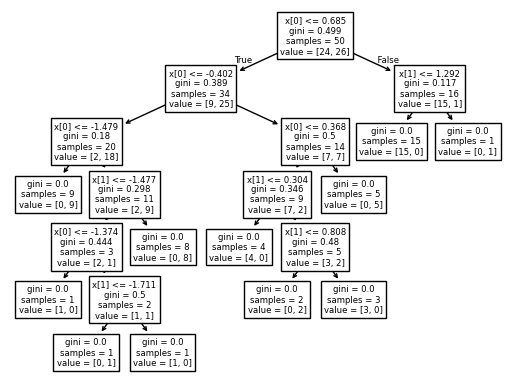

In [18]:
plot_tree(clf1)

[Text(0.4605263157894737, 0.9375, 'x[0] <= 0.928\ngini = 0.497\nsamples = 50\nvalue = [23, 27]'),
 Text(0.21052631578947367, 0.8125, 'x[1] <= 1.688\ngini = 0.375\nsamples = 24\nvalue = [6, 18]'),
 Text(0.3355263157894737, 0.875, 'True  '),
 Text(0.15789473684210525, 0.6875, 'x[0] <= 0.769\ngini = 0.49\nsamples = 14\nvalue = [6, 8]'),
 Text(0.10526315789473684, 0.5625, 'x[0] <= -1.205\ngini = 0.48\nsamples = 10\nvalue = [6, 4]'),
 Text(0.05263157894736842, 0.4375, 'gini = 0.0\nsamples = 2\nvalue = [0, 2]'),
 Text(0.15789473684210525, 0.4375, 'x[1] <= 0.431\ngini = 0.375\nsamples = 8\nvalue = [6, 2]'),
 Text(0.10526315789473684, 0.3125, 'gini = 0.0\nsamples = 3\nvalue = [3, 0]'),
 Text(0.21052631578947367, 0.3125, 'x[1] <= 1.495\ngini = 0.48\nsamples = 5\nvalue = [3, 2]'),
 Text(0.15789473684210525, 0.1875, 'x[0] <= 0.688\ngini = 0.444\nsamples = 3\nvalue = [1, 2]'),
 Text(0.10526315789473684, 0.0625, 'gini = 0.0\nsamples = 2\nvalue = [0, 2]'),
 Text(0.21052631578947367, 0.0625, 'gini = 

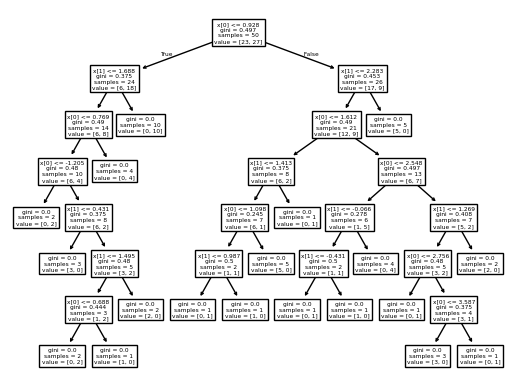

In [19]:
plot_tree(clf2)

[Text(0.5, 0.9166666666666666, 'x[1] <= -0.108\ngini = 0.48\nsamples = 50\nvalue = [30, 20]'),
 Text(0.2777777777777778, 0.75, 'x[1] <= -0.903\ngini = 0.245\nsamples = 28\nvalue = [24, 4]'),
 Text(0.3888888888888889, 0.8333333333333333, 'True  '),
 Text(0.16666666666666666, 0.5833333333333334, 'x[0] <= -0.232\ngini = 0.111\nsamples = 17\nvalue = [16, 1]'),
 Text(0.1111111111111111, 0.4166666666666667, 'x[0] <= -0.282\ngini = 0.245\nsamples = 7\nvalue = [6, 1]'),
 Text(0.05555555555555555, 0.25, 'gini = 0.0\nsamples = 6\nvalue = [6, 0]'),
 Text(0.16666666666666666, 0.25, 'gini = 0.0\nsamples = 1\nvalue = [0, 1]'),
 Text(0.2222222222222222, 0.4166666666666667, 'gini = 0.0\nsamples = 10\nvalue = [10, 0]'),
 Text(0.3888888888888889, 0.5833333333333334, 'x[1] <= -0.672\ngini = 0.397\nsamples = 11\nvalue = [8, 3]'),
 Text(0.3333333333333333, 0.4166666666666667, 'x[0] <= -1.456\ngini = 0.5\nsamples = 6\nvalue = [3, 3]'),
 Text(0.2777777777777778, 0.25, 'gini = 0.0\nsamples = 3\nvalue = [3, 0]

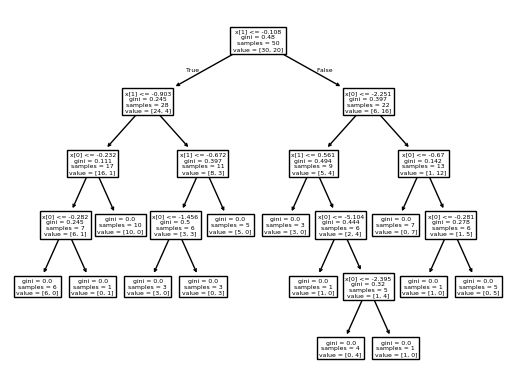

In [20]:
plot_tree(clf3)

In [21]:
clf1.predict(np.array([-1.042498,	-0.064323]).reshape(1,2))

c:\Users\Kaushik Mandal\.virtualenvs\ClassicalML-_wR1sNSC\Lib\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(


array([1])

In [22]:
clf2.predict(np.array([-1.042498,	-0.064323]).reshape(1,2))

c:\Users\Kaushik Mandal\.virtualenvs\ClassicalML-_wR1sNSC\Lib\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(


array([0])

In [23]:
clf3.predict(np.array([-1.042498,	-0.064323]).reshape(1,2))

c:\Users\Kaushik Mandal\.virtualenvs\ClassicalML-_wR1sNSC\Lib\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(


array([1])

- So we can take majority count of the above predictions from the above 3 decision trees to make a final prediction. This is called **voting** in case of classification problems and **averaging** in case of regression problems.

In [24]:
df.sample(14,replace=True)

,col1,col2,col3,col4,col5,target
39,-1.280629,0.407692,-1.522179,-1.013648,-2.155627,1
75,1.454471,-0.840638,-0.328072,0.540640,-2.932864,0
36,0.906744,-0.279044,-3.056911,3.356832,-3.102577,1
99,0.935681,1.614138,-0.491455,0.578889,-0.302403,1
7,1.761032,0.089863,-0.692818,0.231797,-1.865309,1
7,1.761032,0.089863,-0.692818,0.231797,-1.865309,1
98,-0.450970,2.024304,2.046083,-1.307033,-0.676672,0
56,1.716882,-0.117767,0.205556,-0.995775,-1.805278,0
4,0.080898,2.686253,0.645243,-0.818257,1.482801,1
45,-0.330217,1.639908,2.071463,-1.778540,-1.070397,0
